In [262]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import haversine_distances

In [263]:
indego_q4 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q4/indego-trips-2025-q4.csv")
indego_q3 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q3/indego-trips-2025-q3.csv")
indego_q2 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q2/indego-trips-2025-q2.csv")
indego_q1 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q1/indego-trips-2025-q1.csv")

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\981990909.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q4 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q4/indego-trips-2025-q4.csv")
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\981990909.py:2: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q3 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q3/indego-trips-2025-q3.csv")
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\981990909.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q2 = pd.read_csv("C:/Users/bdoc1/Downloads/indego-trips-2025-q2/indego-trips-2025-q2.csv")
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\981990909.py:4: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  indego_q1 = pd.read_csv("C:/Users/

In [264]:
indego_q4.head()

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type
0,1251856736,5,10/1/2025 0:00,10/1/2025 0:05,3382,39.950378,-75.173088,3064,39.938400,-75.173271,29339,30,One Way,Indego30,electric
1,1251858742,38,10/1/2025 0:01,10/1/2025 0:39,3277,39.983059,-75.167381,3277,39.983059,-75.167381,02685,30,Round Trip,Indego30,standard
2,1251857426,15,10/1/2025 0:01,10/1/2025 0:16,3028,39.940609,-75.149582,3100,39.927769,-75.151031,30333,30,One Way,Indego30,electric
3,1251856653,1,10/1/2025 0:04,10/1/2025 0:04,3024,39.948219,-75.209084,3024,39.948219,-75.209084,29577,365,Round Trip,Indego365,electric
4,1251858039,21,10/1/2025 0:04,10/1/2025 0:25,3063,39.946331,-75.169800,3112,39.953732,-75.218246,03684,30,One Way,Indego30,standard


In [265]:
indego_q4.columns

Index(['trip_id', 'duration', 'start_time', 'end_time', 'start_station',
       'start_lat', 'start_lon', 'end_station', 'end_lat', 'end_lon',
       'bike_id', 'plan_duration', 'trip_route_category', 'passholder_type',
       'bike_type'],
      dtype='object')

In [266]:
#Assisted by CHATGPT
indego_2025 = pd.concat([indego_q1, indego_q2, indego_q3, indego_q4], axis = 0)

In [267]:
indego_2025.shape

(1358173, 15)

In [268]:
indego_2025.columns

Index(['trip_id', 'duration', 'start_time', 'end_time', 'start_station',
       'start_lat', 'start_lon', 'end_station', 'end_lat', 'end_lon',
       'bike_id', 'plan_duration', 'trip_route_category', 'passholder_type',
       'bike_type'],
      dtype='object')

In [269]:
indego_2025.dtypes

trip_id                  int64
duration                 int64
start_time              object
end_time                object
start_station            int64
start_lat              float64
start_lon              float64
end_station              int64
end_lat                float64
end_lon                float64
bike_id                 object
plan_duration            int64
trip_route_category     object
passholder_type         object
bike_type               object
dtype: object

In [270]:
#Assisted by CHATGPT
indego_2025['start_station'] = indego_2025['start_station'].astype('category')
indego_2025['end_station'] = indego_2025['end_station'].astype('category')

In [271]:
indego_2025_oneway = indego_2025[indego_2025['trip_route_category'] == 'One Way']

In [272]:
indego_2025_oneway.head()

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,22580,30,One Way,Indego30,electric
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,31417,365,One Way,Indego365,electric
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,31393,1,One Way,Walk-up,electric
4,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,22872,1,One Way,Walk-up,electric
5,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,11872,365,One Way,Indego365,standard


In [273]:
indego_2025_oneway.shape

(1274939, 15)

In [274]:
indego_2025_oneway['start_time']

0            1/1/2025 0:00
1            1/1/2025 0:04
2            1/1/2025 0:05
4            1/1/2025 0:08
5            1/1/2025 0:14
                ...       
325356    12/31/2025 23:53
325357    12/31/2025 23:56
325358    12/31/2025 23:56
325359    12/31/2025 23:56
325360    12/31/2025 23:57
Name: start_time, Length: 1274939, dtype: object

In [275]:
indego_2025_oneway[['start_date', 'start_tod']] = indego_2025_oneway['start_time'].str.split(' ', expand=True)
indego_2025_oneway[['end_date', 'end_tod']] = indego_2025_oneway['end_time'].str.split(' ', expand=True)

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\3237425989.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway[['start_date', 'start_tod']] = indego_2025_oneway['start_time'].str.split(' ', expand=True)
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\3237425989.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway[['start_date', 'start_tod']] = indego_2025_oneway['start_time'].str.split(' ', expand=True)
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\3237425989.py:2: 

In [276]:
indego_2025_oneway['start_tod']

0          0:00
1          0:04
2          0:05
4          0:08
5          0:14
          ...  
325356    23:53
325357    23:56
325358    23:56
325359    23:56
325360    23:57
Name: start_tod, Length: 1274939, dtype: object

In [277]:
#Assisted by CHATGPT
indego_2025_oneway['day_of_week_start'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.day_name()
indego_2025_oneway['day_of_week_end'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.day_name()

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\2838975035.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['day_of_week_start'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.day_name()
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\2838975035.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['day_of_week_end'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.day_name()


In [278]:
indego_2025_oneway['day_of_week_start']

0         Wednesday
1         Wednesday
2         Wednesday
4         Wednesday
5         Wednesday
            ...    
325356    Wednesday
325357    Wednesday
325358    Wednesday
325359    Wednesday
325360    Wednesday
Name: day_of_week_start, Length: 1274939, dtype: object

In [279]:
#Assisted by CHATGPT
indego_2025_oneway['start_month'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.month_name()
indego_2025_oneway['end_month'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.month_name()

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\1606026582.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['start_month'] = pd.to_datetime(indego_2025_oneway['start_date']).dt.month_name()
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\1606026582.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['end_month'] = pd.to_datetime(indego_2025_oneway['end_date']).dt.month_name()


In [280]:
indego_2025_oneway['start_month']

0          January
1          January
2          January
4          January
5          January
            ...   
325356    December
325357    December
325358    December
325359    December
325360    December
Name: start_month, Length: 1274939, dtype: object

In [281]:
indego_2025_oneway['minutes_after_midnight'] = indego_2025_oneway['start_tod'].str.split(":").str[0].astype(int) * 60 + indego_2025_oneway['start_tod'].str.split(":").str[1].astype(int)

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\3755218255.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['minutes_after_midnight'] = indego_2025_oneway['start_tod'].str.split(":").str[0].astype(int) * 60 + indego_2025_oneway['start_tod'].str.split(":").str[1].astype(int)


In [282]:
indego_2025_oneway['minutes_after_midnight']

0            0
1            4
2            5
4            8
5           14
          ... 
325356    1433
325357    1436
325358    1436
325359    1436
325360    1437
Name: minutes_after_midnight, Length: 1274939, dtype: int64

In [283]:
indego_2025_oneway.head()

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,bike_type,start_date,start_tod,end_date,end_tod,day_of_week_start,day_of_week_end,start_month,end_month,minutes_after_midnight
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,electric,1/1/2025,0:00,1/1/2025,0:05,Wednesday,Wednesday,January,January,0
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,electric,1/1/2025,0:04,1/1/2025,0:18,Wednesday,Wednesday,January,January,4
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,electric,1/1/2025,0:05,1/1/2025,14:59,Wednesday,Wednesday,January,January,5
4,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,electric,1/1/2025,0:08,1/1/2025,0:21,Wednesday,Wednesday,January,January,8
5,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,...,standard,1/1/2025,0:14,1/1/2025,0:25,Wednesday,Wednesday,January,January,14


In [284]:
indego_2025_oneway.head()

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,bike_type,start_date,start_tod,end_date,end_tod,day_of_week_start,day_of_week_end,start_month,end_month,minutes_after_midnight
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,electric,1/1/2025,0:00,1/1/2025,0:05,Wednesday,Wednesday,January,January,0
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,electric,1/1/2025,0:04,1/1/2025,0:18,Wednesday,Wednesday,January,January,4
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,electric,1/1/2025,0:05,1/1/2025,14:59,Wednesday,Wednesday,January,January,5
4,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,electric,1/1/2025,0:08,1/1/2025,0:21,Wednesday,Wednesday,January,January,8
5,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,...,standard,1/1/2025,0:14,1/1/2025,0:25,Wednesday,Wednesday,January,January,14


In [285]:
stations = pd.read_csv("C:/Users/bdoc1/OneDrive/Classwork/Temple S1/Statistical Learning and Data Mining/IndegoStations.csv")

In [286]:
stations.columns

Index(['Station_ID,Station_Name,Day of Go_live_date,Status'], dtype='object')

In [287]:
stations[0:20]

,"Station_ID,Station_Name,Day of Go_live_date,Status"
0,"3000,Virtual Station,4/23/2015,Active"
1,"3004,Municipal Services Building Plaza,4/23/20..."
2,"3005,""Welcome Park, NPS"",4/23/2015,Active"
3,"3006,40th & Spruce,4/23/2015,Active"
4,"3007,""11th & Pine, Kahn Park"",4/23/2015,Active"
5,"3008,Temple University Station,4/23/2015,Active"
6,"3009,33rd & Market,4/23/2015,Active"
7,"3010,15th & Spruce,4/23/2015,Active"
8,"3011,38th & Powelton,4/23/2015,Inactive"
9,"3012,21st & Catharine,4/23/2015,Active"


In [288]:
stations['neighborhood'] = ['N/A', 'Logan Square', 'Old City', 'University City', 'Washington Square West', 'Hartranft',
                            'University City', 'Rittenhouse', 'West Powelton', 'Graduate Hospital', 'Northern Liberties',
                            'Logan Square', 'Society Hill', 'Poplar', 'Norris Square', 'Market East', 
                            'Chinatown', 'University City', 'Logan Square', 'University City', 'Rittenhouse',
                            'Spruce Hill', 'Bella Vista', 'Queen Village', 'University City', 'Queen Village',
                            'University City', 'Bella Vista', 'Hartranft', 'Graduate Hospital', 'Market East',
                            'Passyunk Square', 'Mantua', 'Northern Liberties', 'Market East', 'University City',
                            'Cecil B. Moore', 'Spring Garden', 'Fishtown', 'Newbold', 'Washington Square West',
                            'Old City', 'Old City', 'Bella Vista', 'Society Hill', 'Chinatown',
                            'Fairmount', 'Washington Square West', 'Point Breeze', 'Logan Square', 'Market East',
                            'Yorktown', 'Fairmount', 'Fairmount', 'Poplar', 'Logan Square',
                            'Logan Square', 'Fitler Square', 'Rittenhouse', 'Point Breeze', 'Ludlow',
                            'Rittenhouse', 'Mantua', 'Passyunk Square', 'Queen Village', 'Northern Liberties',
                            'Powelton Village', 'Queen Village', 'Callowhill', 'Spruce Hill', 'Spring Garden',
                            'Cecil B. Moore', 'Logan Square', 'Graduate Hospital', 'Olde Kensington', 'Strawberry Mansion',
                            'Strawberry Mansion', 'Strawberry Mansion', 'Fishtown', 'Passyunk Square', 'Dickinson Narrows',
                            'Pennsport', 'Washington Square West', 'Fairmount', 'Brewerytown', 'Mantua',
                            'Fishtown', 'Strawberry Mansion', 'Strawberry Mansion', 'Logan Square', 'East Parkside',
                            'Northern Liberties', 'Fairmount Park', 'Walnut Hill', 'Fairmount Park', 'Point Breeze',
                            'Cecil B. Moore', 'Logan Square', 'West Parkside', 'Mill Creek', 'Belmont', 
                            'Brewerytown', 'Brewerytown', 'Cecil B. Moore', 'Cecil B. Moore', 'Old City', 
                            'Rittenhouse', 'University City', 'Newbold', 'University City', 'Fishtown',
                            'Callowhill', 'Bella Vista', 'Logan Square', 'East Passyunk Crossing', 'East Passyunk Crossing',
                            'University City', 'University City', 'University City', 'Devils Pocket', 'Fitler Square',
                            'East Passyunk Crossing', 'Logan Square', 'Fishtown', 'Market East', 'Rittenhouse',
                            'Old City', 'Devils Pocket', 'Navy Yard', 'Rittenhouse', 'Navy Yard',
                            'University City', 'Market East', 'Navy Yard', 'Logan Square', 'Packer Park',
                            'Rittenhouse', 'Northern Liberties', 'Logan Square', 'Strawberry Mansion', 'Lower Moyamensing',
                            'Cecil B. Moore', 'Logan Square', 'Rittenhouse', 'Graduate Hospital', 'Spring Garden',
                            'Logan Square', 'Rittenhouse', 'University City', 'University City', 'Spruce Hill',
                            'Cecil B. Moore', 'Fairmount', 'Logan Square', 'Graduate Hospital', 'Cecil B. Moore',
                            'Norris Square', 'Chinatown', 'Logan Square', 'Logan Square', 'Fairmount',
                            'Lower Moyamensing', 'Washington Square West', 'Mill Creek', 'Cobbs Creek', 'Hartranft',
                            'Graduate Hospital', 'Hartranft', 'Cedar Park', 'Mill Creek', 'Graduate Hospital',
                            'Powelton Village', 'Old City', 'Grays Ferry', 'Grays Ferry', 'Grays Ferry',
                            'Cecil B. Moore', 'Rittenhouse', 'Fitler Square', 'Whitman', 'Cobbs Creek',
                            'West Powelton', 'Northern Liberties', 'West Powelton', 'Washington Square West', 'Powelton Village',
                            'Pennsport', 'Girard Estates', 'Angora', 'Mill Creek', 'East Falls',
                            'Olde Richmond', 'Poplar', 'Cecil B. Moore', 'Strawberry Mansion', 'East Passyunk Crossing',
                            'Kingsessing', 'Kingsessing', 'Hartranft', 'East Falls', 'Northern Liberties', 
                            'Northern Liberties', 'Squirrel Hill', 'East Falls', 'Rittenhouse', 'Market East',
                            'Rittenhouse', 'Spruce Hill', 'Washington Square West', 'Market East', 'Sharswood',
                            'Whitman', 'Logan Square', 'Rittenhouse', 'University City', 'Washington Square West',
                            'Allegheny West', 'Strawberry Mansion', 'Allegheny West', 'Bella Vista', 'Cobbs Creek',
                            'Brewerytown', 'Whitman', 'Lower Moyamensing', 'Queen Village', 'Kingsessing',
                            'Melrose', 'Grays Ferry', 'Market East', 'Fishtown', 'Cecil B. Moore',
                            'Logan Square', 'Bella Vista', 'Manayunk', 'Fairmount Park', 'Fairmount Park',
                            'Fishtown', 'Fairmount Park', 'Manayunk', 'Logan Square', 'Fishtown',
                            'Allegheny West', 'Passyunk Square', 'Manayunk', 'University City', 'Ludlow',
                            'Cobbs Creek', 'Manayunk', 'Fairmount', 'Yorktown', 'Fishtown',
                            'Logan Square', 'Olde Richmond', 'Fairmount', 'Point Breeze', 'Cobbs Creek',
                            'Northern Liberties', 'Old City', 'Chinatown', 'Brewerytown', 'Grays Ferry',
                            'Glenwood', 'Glenwood', 'Nicetown-Tioga', 'Franklinville', 'Cobbs Creek',
                            'Lower Moyamensing', 'Navy Yard', 'Packer Park', 'Fishtown', 'Rittenhouse',
                            'Point Breeze', 'Point Breeze', 'Market East', 'Powelton Village', 'Haddington',
                            'Sharswood', 'Washington Square West', 'Washington Square West', 'East Falls', 'Manayunk',
                            'Chinatown', 'West Passyunk', 'Callowhill', 'Northern Liberties', 'Ludlow',
                            'West Passyunk', 'Old City', 'Olde Kensington', 'Cedar Park', 'Rittenhouse',
                            'Northern Liberties', 'Fairmount', 'Poplar', 'Poplar', 'Dunlap',
                            'Wynnefield', 'Grays Ferry', 'Northern Liberties', 'Lower Moyamensing', 'Bella Vista',
                            'West Passyunk', 'Point Breeze', 'Whitman', 'Market East', 'Devils Pocket', 
                            'Olde Kensington', 'Washington Square West', 'Bella Vista', 'Norris Square', 'Whitman',
                            'Chinatown', 'Kingsessing', 'Haddington', 'Wynnefield', 'Kingsessing',
                            'Kingsessing', 'Hartranft', 'Nicetown-Tioga', 'Lower Moyamensing', 'University City',
                            'Kensington', 'Brewerytown', 'Carroll Park', 'Manayunk', 'Olde Richmond', 
                            'Cobbs Creek', 'Fishtown', 'Kensington', 'Port Richmond', 'Grays Ferry',
                            'Port Richmond', 'Kensington', 'Port Richmond', 'Fairmount', 'Mill Creek',
                            'Kingsessing', 'Overbrook', 'Manayunk', 'Manayunk', 'Nicetown-Tioga',
                            'Fishtown', 'Overbrook', 'Old City', 'Bella Vista']

In [289]:
len(stations['neighborhood'].unique())

72

In [290]:
stations.head

<bound method NDFrame.head of     Station_ID,Station_Name,Day of Go_live_date,Status            neighborhood
0                3000,Virtual Station,4/23/2015,Active                     N/A
1    3004,Municipal Services Building Plaza,4/23/20...            Logan Square
2            3005,"Welcome Park, NPS",4/23/2015,Active                Old City
3                  3006,40th & Spruce,4/23/2015,Active         University City
4       3007,"11th & Pine, Kahn Park",4/23/2015,Active  Washington Square West
..                                                 ...                     ...
340              3444,23rd & Venango,11/12/2025,Active          Nicetown-Tioga
341           3445,Frankford & Crease,11/7/2025,Active                Fishtown
342           3446,Overbrook Station,11/29/2025,Active               Overbrook
343                3447,2nd & Market,12/10/2025,Active                Old City
344      3448,Broad & Christian East,12/12/2025,Active             Bella Vista

[345 rows x 2 columns

In [291]:
stations.columns

Index(['Station_ID,Station_Name,Day of Go_live_date,Status', 'neighborhood'], dtype='object')

In [292]:
stations[['Station_ID', 'Station_Name' , 'Day of Go_live_date', 'Status']] = (
    stations['Station_ID,Station_Name,Day of Go_live_date,Status']
    .str.split(',(?=(?:[^"]*"[^"]*")*[^"]*$)', expand=True)
)

In [293]:
stations.head

<bound method NDFrame.head of     Station_ID,Station_Name,Day of Go_live_date,Status  \
0                3000,Virtual Station,4/23/2015,Active   
1    3004,Municipal Services Building Plaza,4/23/20...   
2            3005,"Welcome Park, NPS",4/23/2015,Active   
3                  3006,40th & Spruce,4/23/2015,Active   
4       3007,"11th & Pine, Kahn Park",4/23/2015,Active   
..                                                 ...   
340              3444,23rd & Venango,11/12/2025,Active   
341           3445,Frankford & Crease,11/7/2025,Active   
342           3446,Overbrook Station,11/29/2025,Active   
343                3447,2nd & Market,12/10/2025,Active   
344      3448,Broad & Christian East,12/12/2025,Active   

               neighborhood Station_ID                       Station_Name  \
0                       N/A       3000                    Virtual Station   
1              Logan Square       3004  Municipal Services Building Plaza   
2                  Old City       3005    

In [294]:
stations.drop('Station_ID,Station_Name,Day of Go_live_date,Status', axis=1, inplace=True)

In [295]:
stations.head

<bound method NDFrame.head of                neighborhood Station_ID                       Station_Name  \
0                       N/A       3000                    Virtual Station   
1              Logan Square       3004  Municipal Services Building Plaza   
2                  Old City       3005                "Welcome Park, NPS"   
3           University City       3006                      40th & Spruce   
4    Washington Square West       3007           "11th & Pine, Kahn Park"   
..                      ...        ...                                ...   
340          Nicetown-Tioga       3444                     23rd & Venango   
341                Fishtown       3445                 Frankford & Crease   
342               Overbrook       3446                  Overbrook Station   
343                Old City       3447                       2nd & Market   
344             Bella Vista       3448             Broad & Christian East   

    Day of Go_live_date    Status  
0        

In [296]:
stations_table = stations.groupby('Status').size()
stations_table

Status
Active      292
Inactive     53
dtype: int64

In [297]:
indego_2025_oneway.dtypes

trip_id                      int64
duration                     int64
start_time                  object
end_time                    object
start_station             category
start_lat                  float64
start_lon                  float64
end_station               category
end_lat                    float64
end_lon                    float64
bike_id                     object
plan_duration                int64
trip_route_category         object
passholder_type             object
bike_type                   object
start_date                  object
start_tod                   object
end_date                    object
end_tod                     object
day_of_week_start           object
day_of_week_end             object
start_month                 object
end_month                   object
minutes_after_midnight       int64
dtype: object

In [298]:
stations.dtypes

neighborhood           object
Station_ID             object
Station_Name           object
Day of Go_live_date    object
Status                 object
dtype: object

In [299]:
stations['Station_ID'] = stations['Station_ID'].astype('category')

In [300]:
indego_2025_oneway.head(10)

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,bike_type,start_date,start_tod,end_date,end_tod,day_of_week_start,day_of_week_end,start_month,end_month,minutes_after_midnight
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,electric,1/1/2025,0:00,1/1/2025,0:05,Wednesday,Wednesday,January,January,0
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,electric,1/1/2025,0:04,1/1/2025,0:18,Wednesday,Wednesday,January,January,4
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,electric,1/1/2025,0:05,1/1/2025,14:59,Wednesday,Wednesday,January,January,5
4,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,electric,1/1/2025,0:08,1/1/2025,0:21,Wednesday,Wednesday,January,January,8
5,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,...,standard,1/1/2025,0:14,1/1/2025,0:25,Wednesday,Wednesday,January,January,14
6,1123986634,15,1/1/2025 0:14,1/1/2025 0:29,3049,39.945091,-75.142502,3100,39.927769,-75.151031,...,standard,1/1/2025,0:14,1/1/2025,0:29,Wednesday,Wednesday,January,January,14
7,1123986963,19,1/1/2025 0:18,1/1/2025 0:37,3112,39.953732,-75.218246,3035,39.962711,-75.194191,...,standard,1/1/2025,0:18,1/1/2025,0:37,Wednesday,Wednesday,January,January,18
8,1123987027,20,1/1/2025 0:18,1/1/2025 0:38,3124,39.953671,-75.139557,3341,39.981312,-75.127319,...,standard,1/1/2025,0:18,1/1/2025,0:38,Wednesday,Wednesday,January,January,18
9,1123987228,24,1/1/2025 0:18,1/1/2025 0:42,3124,39.953671,-75.139557,3394,39.924000,-75.169594,...,electric,1/1/2025,0:18,1/1/2025,0:42,Wednesday,Wednesday,January,January,18
10,1123987518,26,1/1/2025 0:19,1/1/2025 0:45,3124,39.953671,-75.139557,3313,39.915798,-75.164299,...,electric,1/1/2025,0:19,1/1/2025,0:45,Wednesday,Wednesday,January,January,19


In [301]:
indego_2025_oneway.head(10)

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,bike_type,start_date,start_tod,end_date,end_tod,day_of_week_start,day_of_week_end,start_month,end_month,minutes_after_midnight
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,electric,1/1/2025,0:00,1/1/2025,0:05,Wednesday,Wednesday,January,January,0
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,electric,1/1/2025,0:04,1/1/2025,0:18,Wednesday,Wednesday,January,January,4
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,electric,1/1/2025,0:05,1/1/2025,14:59,Wednesday,Wednesday,January,January,5
4,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,electric,1/1/2025,0:08,1/1/2025,0:21,Wednesday,Wednesday,January,January,8
5,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,...,standard,1/1/2025,0:14,1/1/2025,0:25,Wednesday,Wednesday,January,January,14
6,1123986634,15,1/1/2025 0:14,1/1/2025 0:29,3049,39.945091,-75.142502,3100,39.927769,-75.151031,...,standard,1/1/2025,0:14,1/1/2025,0:29,Wednesday,Wednesday,January,January,14
7,1123986963,19,1/1/2025 0:18,1/1/2025 0:37,3112,39.953732,-75.218246,3035,39.962711,-75.194191,...,standard,1/1/2025,0:18,1/1/2025,0:37,Wednesday,Wednesday,January,January,18
8,1123987027,20,1/1/2025 0:18,1/1/2025 0:38,3124,39.953671,-75.139557,3341,39.981312,-75.127319,...,standard,1/1/2025,0:18,1/1/2025,0:38,Wednesday,Wednesday,January,January,18
9,1123987228,24,1/1/2025 0:18,1/1/2025 0:42,3124,39.953671,-75.139557,3394,39.924000,-75.169594,...,electric,1/1/2025,0:18,1/1/2025,0:42,Wednesday,Wednesday,January,January,18
10,1123987518,26,1/1/2025 0:19,1/1/2025 0:45,3124,39.953671,-75.139557,3313,39.915798,-75.164299,...,electric,1/1/2025,0:19,1/1/2025,0:45,Wednesday,Wednesday,January,January,19


In [302]:
stations.dtypes

neighborhood             object
Station_ID             category
Station_Name             object
Day of Go_live_date      object
Status                   object
dtype: object

In [303]:
indego_2025_oneway['start_station'][0]

0    3371
0    3022
0    3163
0    3382
Name: start_station, dtype: category
Categories (297, int64): [3000, 3005, 3006, 3007, ..., 3445, 3446, 3447, 3448]

In [304]:
stations['Station_ID'][281]

'3371'

In [305]:
indego_2025_oneway['start_station'] = pd.Categorical(indego_2025_oneway['start_station'])
indego_2025_oneway['end_station'] = pd.Categorical(indego_2025_oneway['end_station'])

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\3928698366.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['start_station'] = pd.Categorical(indego_2025_oneway['start_station'])
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\3928698366.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['end_station'] = pd.Categorical(indego_2025_oneway['end_station'])


In [306]:
indego_2025_oneway['start_station'][0]

0    3371
0    3022
0    3163
0    3382
Name: start_station, dtype: category
Categories (297, int64): [3000, 3005, 3006, 3007, ..., 3445, 3446, 3447, 3448]

In [307]:
indego_2025_oneway['start_station'] = indego_2025_oneway['start_station'].astype(str)
indego_2025_oneway['end_station'] = indego_2025_oneway['end_station'].astype(str)

C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\2707131073.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['start_station'] = indego_2025_oneway['start_station'].astype(str)
C:\Users\bdoc1\AppData\Local\Temp\ipykernel_4532\2707131073.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  indego_2025_oneway['end_station'] = indego_2025_oneway['end_station'].astype(str)


In [308]:
indego_2025_oneway['start_station'][0]

0    3371
0    3022
0    3163
0    3382
Name: start_station, dtype: object

In [309]:
indego_2025_oneway = indego_2025_oneway.merge(
    stations[['Station_ID', 'Station_Name', 'neighborhood']],
    left_on = 'start_station',
    right_on = 'Station_ID',
    how = 'left')
indego_2025_oneway = indego_2025_oneway.rename(columns={
    'Station_Name': 'Start_Station_Name',
    'neighborhood': 'Start_Neighborhood'
})
indego_2025_oneway = indego_2025_oneway.drop('Station_ID', axis=1)
indego_2025_oneway = indego_2025_oneway.merge(
    stations[['Station_ID', 'Station_Name', 'neighborhood']],
    left_on = 'end_station',
    right_on = 'Station_ID',
    how = 'left')
indego_2025_oneway = indego_2025_oneway.rename(columns={
    'Station_Name': 'End_Station_Name',
    'neighborhood': 'End_Neighborhood'
})
indego_2025_oneway = indego_2025_oneway.drop('Station_ID', axis=1)

In [310]:
indego_2025_oneway.head(10)

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,end_tod,day_of_week_start,day_of_week_end,start_month,end_month,minutes_after_midnight,Start_Station_Name,Start_Neighborhood,End_Station_Name,End_Neighborhood
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,0:05,Wednesday,Wednesday,January,January,0,9th & Arch,Chinatown,4th & Arch,Old City
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,0:18,Wednesday,Wednesday,January,January,4,56th & Chestnut,Cobbs Creek,18th & Chestnut,Rittenhouse
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,14:59,Wednesday,Wednesday,January,January,5,18th & JFK,Logan Square,9th & Spring Garden,Callowhill
3,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,0:21,Wednesday,Wednesday,January,January,8,17th & Sansom,Rittenhouse,34th & Arch,Powelton Village
4,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,...,0:25,Wednesday,Wednesday,January,January,14,6th & Chestnut,Old City,Virtual Station,N/A
5,1123986634,15,1/1/2025 0:14,1/1/2025 0:29,3049,39.945091,-75.142502,3100,39.927769,-75.151031,...,0:29,Wednesday,Wednesday,January,January,14,Foglietta Plaza,Society Hill,Moyamensing & Tasker,Pennsport
6,1123986963,19,1/1/2025 0:18,1/1/2025 0:37,3112,39.953732,-75.218246,3035,39.962711,-75.194191,...,0:37,Wednesday,Wednesday,January,January,18,48th & Spruce,Walnut Hill,Dornsife Center,Mantua
7,1123987027,20,1/1/2025 0:18,1/1/2025 0:38,3124,39.953671,-75.139557,3341,39.981312,-75.127319,...,0:38,Wednesday,Wednesday,January,January,18,Race Street Pier,Old City,York & Trenton,Olde Richmond
8,1123987228,24,1/1/2025 0:18,1/1/2025 0:42,3124,39.953671,-75.139557,3394,39.924000,-75.169594,...,0:42,Wednesday,Wednesday,January,January,18,Race Street Pier,Old City,Broad & Snyder,Lower Moyamensing
9,1123987518,26,1/1/2025 0:19,1/1/2025 0:45,3124,39.953671,-75.139557,3313,39.915798,-75.164299,...,0:45,Wednesday,Wednesday,January,January,19,Race Street Pier,Old City,10th & Oregon,Lower Moyamensing


In [311]:
indego_2025_oneway['route'] = (indego_2025_oneway['Start_Neighborhood'] + ' to ' + indego_2025_oneway['End_Neighborhood'])
indego_2025_oneway['route_type'] = np.where(indego_2025_oneway['Start_Neighborhood'] == indego_2025_oneway['End_Neighborhood'],
                                            'Intraneighborhood', 'Interneighborhood')

In [312]:
indego_2025_oneway['Start_Neighborhood'].unique()

array(['Chinatown', 'Cobbs Creek', 'Logan Square', 'Rittenhouse',
       'Old City', 'Society Hill', 'Walnut Hill', 'Point Breeze',
       'Bella Vista', 'University City', 'Fairmount',
       'Northern Liberties', 'Cecil B. Moore', 'Fishtown',
       'East Passyunk Crossing', 'Queen Village',
       'Washington Square West', 'Olde Kensington', 'Poplar',
       'Callowhill', 'Graduate Hospital', 'Fitler Square', 'Market East',
       'Strawberry Mansion', 'Spring Garden', 'Mantua', 'Olde Richmond',
       'Cedar Park', 'Pennsport', 'Dickinson Narrows', 'Passyunk Square',
       'Grays Ferry', 'Lower Moyamensing', 'Powelton Village',
       'Packer Park', 'Manayunk', 'Newbold', 'Hartranft', 'Spruce Hill',
       'Norris Square', 'Ludlow', 'Devils Pocket', 'West Powelton',
       'East Falls', 'Brewerytown', 'Fairmount Park', 'Sharswood',
       'Girard Estates', 'Yorktown', 'Whitman', 'West Passyunk',
       'Squirrel Hill', 'Mill Creek', 'Belmont', 'Angora', 'Dunlap',
       'Kingsessi

In [313]:
neighborhood_rides = indego_2025_oneway.groupby('route').size()
neighborhood_rides.sort_values(inplace=True,ascending= False)

In [314]:
neighborhood_rides.head(20)

route
University City to University City                  21237
Logan Square to Logan Square                        16325
Rittenhouse to University City                      15177
University City to Rittenhouse                      15152
University City to Logan Square                     12910
Logan Square to Fairmount                           12888
Logan Square to University City                     12651
Fairmount to Logan Square                           12597
Washington Square West to Rittenhouse               12544
Rittenhouse to Washington Square West               12257
Rittenhouse to Rittenhouse                          12124
Rittenhouse to Logan Square                         11571
Logan Square to Rittenhouse                         11369
Washington Square West to Washington Square West    10741
Rittenhouse to Graduate Hospital                    10321
University City to Graduate Hospital                10303
Graduate Hospital to Rittenhouse                    10278
Rittenho

In [315]:
rides_by_day_of_week = indego_2025_oneway.groupby('day_of_week_start').size()
rides_by_day_of_week.sort_values(inplace=True,ascending= False)

In [316]:
rides_by_day_of_week

day_of_week_start
Thursday     196373
Tuesday      196036
Friday       194020
Wednesday    193261
Monday       176094
Saturday     168807
Sunday       150348
dtype: int64

In [317]:
weekday = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
weekend = ['Saturday', 'Sunday']
weekday_rides = indego_2025_oneway[indego_2025_oneway['day_of_week_start'].isin(weekday)]
weekend_rides = indego_2025_oneway[indego_2025_oneway['day_of_week_start'].isin(weekend)]

In [318]:
weekday_rides.head(5)

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,...,day_of_week_end,start_month,end_month,minutes_after_midnight,Start_Station_Name,Start_Neighborhood,End_Station_Name,End_Neighborhood,route,route_type
0,1123985990,5,1/1/2025 0:00,1/1/2025 0:05,3371,39.953400,-75.154297,3378,39.952381,-75.147278,...,Wednesday,January,January,0,9th & Arch,Chinatown,4th & Arch,Old City,Chinatown to Old City,Interneighborhood
1,1123986350,14,1/1/2025 0:04,1/1/2025 0:18,3344,39.959610,-75.233543,3294,39.951740,-75.170631,...,Wednesday,January,January,4,56th & Chestnut,Cobbs Creek,18th & Chestnut,Rittenhouse,Cobbs Creek to Rittenhouse,Interneighborhood
2,1124202498,894,1/1/2025 0:05,1/1/2025 14:59,3021,39.953899,-75.169022,3073,39.961430,-75.152420,...,Wednesday,January,January,5,18th & JFK,Logan Square,9th & Spring Garden,Callowhill,Logan Square to Callowhill,Interneighborhood
3,1123986414,13,1/1/2025 0:08,1/1/2025 0:21,3182,39.950809,-75.169533,3249,39.957840,-75.190788,...,Wednesday,January,January,8,17th & Sansom,Rittenhouse,34th & Arch,Powelton Village,Rittenhouse to Powelton Village,Interneighborhood
4,1124234277,11,1/1/2025 0:14,1/1/2025 0:25,3346,39.948830,-75.150970,3000,NaN,NaN,...,Wednesday,January,January,14,6th & Chestnut,Old City,Virtual Station,N/A,Old City to N/A,Interneighborhood


In [319]:
neighborhood_rides_weekday = weekday_rides.groupby('route').size()
neighborhood_rides_weekday.sort_values(inplace=True,ascending= False)
neighborhood_rides_weekend = weekend_rides.groupby('route').size()
neighborhood_rides_weekend.sort_values(inplace=True,ascending= False)

In [320]:
neighborhood_rides_weekday.head(20)

route
University City to University City                  17312
Rittenhouse to University City                      12562
University City to Rittenhouse                      12522
Logan Square to Logan Square                        12277
University City to Logan Square                     10823
Logan Square to University City                     10606
Logan Square to Fairmount                            9839
Fairmount to Logan Square                            9714
Washington Square West to Rittenhouse                9381
Rittenhouse to Washington Square West                9143
Rittenhouse to Rittenhouse                           9047
University City to Graduate Hospital                 8993
Rittenhouse to Logan Square                          8831
Logan Square to Rittenhouse                          8598
Washington Square West to Washington Square West     7941
Rittenhouse to Graduate Hospital                     7879
Graduate Hospital to Rittenhouse                     7745
Graduate

In [321]:
neighborhood_rides_weekend.head(20)

route
Logan Square to Logan Square                        4048
University City to University City                  3925
Washington Square West to Rittenhouse               3163
Rittenhouse to Washington Square West               3114
Rittenhouse to Rittenhouse                          3077
Logan Square to Fairmount                           3049
Fairmount to Logan Square                           2883
Washington Square West to Washington Square West    2800
Logan Square to Rittenhouse                         2771
Rittenhouse to Logan Square                         2740
University City to Rittenhouse                      2630
Rittenhouse to University City                      2615
Graduate Hospital to Rittenhouse                    2533
Rittenhouse to Graduate Hospital                    2442
University City to Logan Square                     2087
Fairmount to Fairmount                              2081
Logan Square to University City                     2045
Rittenhouse to Point Bree

In [322]:
rides_by_month = indego_2025_oneway.groupby('start_month').size()
rides_by_month.sort_values(inplace=True,ascending= False)

In [323]:
rides_by_month

start_month
September    157040
August       145356
October      142084
July         132122
June         123394
May          116542
November     102697
April        101124
March         85145
December      63788
February      57258
January       48389
dtype: int64

In [324]:
rides_by_date = indego_2025_oneway.groupby('start_date').size()
rides_by_date.sort_values(inplace=True,ascending= False)

In [325]:
rides_by_date.head(20)

start_date
9/11/2025    6134
9/3/2025     6066
9/18/2025    6044
9/9/2025     5969
9/30/2025    5887
10/1/2025    5846
9/5/2025     5820
9/19/2025    5767
9/26/2025    5765
9/12/2025    5752
9/4/2025     5720
9/20/2025    5631
8/27/2025    5626
8/26/2025    5596
10/7/2025    5554
10/9/2025    5540
9/8/2025     5538
9/10/2025    5511
10/2/2025    5507
9/2/2025     5489
dtype: int64

In [326]:
uc_intra = indego_2025_oneway[indego_2025_oneway['route'] == 'University City to University City']

<Axes: >

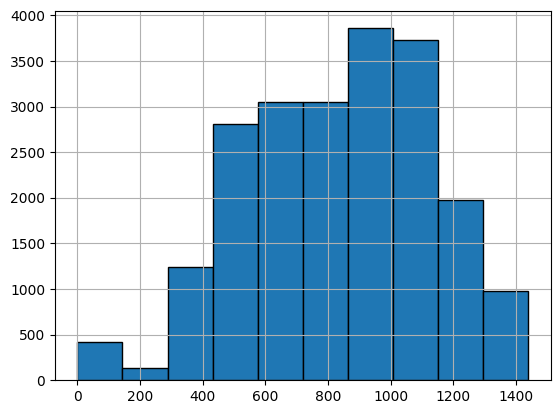

In [327]:
uc_intra['minutes_after_midnight'].hist(edgecolor='black')

<Axes: >

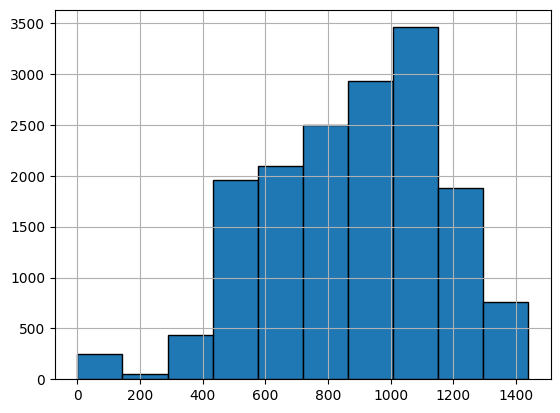

In [328]:
lsq_intra = indego_2025_oneway[indego_2025_oneway['route'] == 'Logan Square to Logan Square']
lsq_intra['minutes_after_midnight'].hist(edgecolor='black')

In [329]:
stations_in_lsq = lsq_intra.groupby('Start_Station_Name').size()
stations_in_lsq.sort_values(inplace=True,ascending= False)

In [330]:
stations_in_lsq

Start_Station_Name
Rodin Museum                                      2076
24th & Race SRT                                   1544
23rd & Market                                     1276
20th & Market                                     1134
Schuylkill Banks Pergola                          1020
16th & Callowhill                                  997
16th & Arch                                        943
Barnes Foundation                                  926
17th & JFK                                         925
18th & JFK                                         905
19th & Market                                      855
18th & JFK Curbside                                670
20th & Cuthbert                                    666
20th & Race                                        639
"21st & Winter, Franklin Institute"                622
18th & Vine                                        570
Free Library of Philadelphia - Central Library     557
dtype: int64

In [331]:
all_stations = indego_2025_oneway.groupby('Start_Station_Name').size().reset_index(name='start_count')
all_stations.sort_values(inplace=True,ascending= False, by='start_count')

In [332]:
all_stations.head(20)

,Start_Station_Name,start_count
61,15th & Spruce,22506
102,23rd & South,17133
211,Broad & Carpenter,15146
70,17th & Locust,14756
286,University City Station,14497
161,4th & Bainbridge,13678
41,11th & Market,13310
80,19th & Lombard,13036
130,30th Street Station East,12814
208,Amtrak 30th Street Station,12499


In [333]:
indego_2025_q1_novirtual = indego_q1[indego_q1['end_station'] != 3000]

In [334]:
indego_2025_oneway_novirtual = indego_2025_oneway[indego_2025_oneway['end_station'] != '3000']
all_stations_end = indego_2025_oneway_novirtual.groupby('End_Station_Name').size().reset_index(name='end_count')
all_stations_end.sort_values(inplace=True,ascending= False, by = 'end_count')

In [335]:
station_coords = (
    indego_2025_oneway_novirtual[['End_Station_Name', 'end_lat', 'end_lon']]
    .drop_duplicates(subset='End_Station_Name')
)

all_stations_end = all_stations_end.merge(
    station_coords,
    on='End_Station_Name',
    how='left',
    indicator='merge_check'
)

In [336]:
all_stations_end

,End_Station_Name,end_count,end_lat,end_lon,merge_check
0,15th & Spruce,22130,39.947109,-75.166183,both
1,23rd & South,16866,39.945271,-75.179710,both
2,Broad & Carpenter,15216,39.938648,-75.166740,both
3,17th & Locust,14529,39.948879,-75.169777,both
4,4th & Bainbridge,13706,39.940609,-75.149582,both
...,...,...,...,...,...
289,"""Manayunk & Conarroe, Fairview Park""",31,40.030548,-75.219833,both
290,23rd & Venango,12,40.009590,-75.165962,both
291,57th & Diamond,6,39.987068,-75.237221,both
292,58th & Kingsessing,1,39.934479,-75.227638,both


In [337]:
indego_2025_oneway_novirtual.columns

Index(['trip_id', 'duration', 'start_time', 'end_time', 'start_station',
       'start_lat', 'start_lon', 'end_station', 'end_lat', 'end_lon',
       'bike_id', 'plan_duration', 'trip_route_category', 'passholder_type',
       'bike_type', 'start_date', 'start_tod', 'end_date', 'end_tod',
       'day_of_week_start', 'day_of_week_end', 'start_month', 'end_month',
       'minutes_after_midnight', 'Start_Station_Name', 'Start_Neighborhood',
       'End_Station_Name', 'End_Neighborhood', 'route', 'route_type'],
      dtype='object')

In [338]:
active_stations_clean = all_stations_end.dropna(subset=['end_lat', 'end_lon'])
# Convert to radians
coords_rad = np.radians(active_stations_clean[['end_lat', 'end_lon']].values)

# Calculate distances in radians
distance_rad = haversine_distances(coords_rad)

distance_miles = distance_rad * 3959

station_distances = pd.DataFrame(
    distance_miles,
    index=active_stations_clean['End_Station_Name'].values,
    columns=active_stations_clean['End_Station_Name'].values
)

In [339]:
nearest_station = pd.DataFrame({
    'station': station_distances.index,
    'nearest_station': station_distances.apply(
        lambda row: row[row > 0].idxmin(), axis=1
    ),
    'distance_miles': station_distances.apply(
        lambda row: row[row > 0].min(), axis=1
    )
})

In [340]:
all_stations_end = all_stations_end.merge(
    nearest_station[['station', 'nearest_station', 'distance_miles']],
    left_on = 'End_Station_Name',
    right_on = 'station',
    how = 'outer')

In [342]:
all_stations_end.head(20)

,End_Station_Name,end_count,end_lat,end_lon,merge_check,station,nearest_station,distance_miles
0,"""11th & Pine, Kahn Park""",10199,39.945171,-75.159927,both,"""11th & Pine, Kahn Park""",11th & South,0.154664
1,"""11th & Poplar, John F. Street Community Center""",1522,39.968922,-75.154701,both,"""11th & Poplar, John F. Street Community Center""",Girard & Hutchinson,0.200367
2,"""15th & Castle, DiSilvestro Playground""",5456,39.928841,-75.170212,both,"""15th & Castle, DiSilvestro Playground""",Broad & Passyunk,0.237636
3,"""18th & Fernon, Aquinas Center""",7919,39.930820,-75.174744,both,"""18th & Fernon, Aquinas Center""","""15th & Castle, DiSilvestro Playground""",0.276339
4,"""18th & Washington, Chew Playground""",8660,39.938400,-75.173271,both,"""18th & Washington, Chew Playground""",18th & Christian,0.172036
5,"""19th & Girard, PTTI""",1880,39.972630,-75.167572,both,"""19th & Girard, PTTI""",Corinthian & Poplar,0.172230
6,"""21st & Winter, Franklin Institute""",2788,39.958858,-75.173691,both,"""21st & Winter, Franklin Institute""",Barnes Foundation,0.122845
7,"""32nd & Baring, Drexel Park""",4769,39.961731,-75.187881,both,"""32nd & Baring, Drexel Park""",34th & Arch,0.309822
8,"""39th & Mt. Vernon, Mantua Haverford Community...",1369,39.964111,-75.199730,both,"""39th & Mt. Vernon, Mantua Haverford Community...",Saunders & Pearl,0.289394
9,"""3rd & Wildey, Liberty Lands Park""",3985,39.966339,-75.142220,both,"""3rd & Wildey, Liberty Lands Park""",2nd & George,0.134387


In [343]:
unique_end_stations =  indego_2025_oneway[['End_Station_Name', 'end_lat', 'end_lon']].drop_duplicates(subset='End_Station_Name')

In [344]:
unique_end_stations.head(20)

,End_Station_Name,end_lat,end_lon
0,4th & Arch,39.952381,-75.147278
1,18th & Chestnut,39.951740,-75.170631
2,9th & Spring Garden,39.961430,-75.152420
3,34th & Arch,39.957840,-75.190788
4,Virtual Station,NaN,NaN
5,Moyamensing & Tasker,39.927769,-75.151031
6,Dornsife Center,39.962711,-75.194191
7,York & Trenton,39.981312,-75.127319
8,Broad & Snyder,39.924000,-75.169594
9,10th & Oregon,39.915798,-75.164299


In [345]:
all_stations_end = all_stations_end.merge(
    unique_end_stations,
    on = 'End_Station_Name',
    how = 'left')

In [346]:
all_stations_end.head(20)

,End_Station_Name,end_count,end_lat_x,end_lon_x,merge_check,station,nearest_station,distance_miles,end_lat_y,end_lon_y
0,"""11th & Pine, Kahn Park""",10199,39.945171,-75.159927,both,"""11th & Pine, Kahn Park""",11th & South,0.154664,39.945171,-75.159927
1,"""11th & Poplar, John F. Street Community Center""",1522,39.968922,-75.154701,both,"""11th & Poplar, John F. Street Community Center""",Girard & Hutchinson,0.200367,39.968922,-75.154701
2,"""15th & Castle, DiSilvestro Playground""",5456,39.928841,-75.170212,both,"""15th & Castle, DiSilvestro Playground""",Broad & Passyunk,0.237636,39.928841,-75.170212
3,"""18th & Fernon, Aquinas Center""",7919,39.930820,-75.174744,both,"""18th & Fernon, Aquinas Center""","""15th & Castle, DiSilvestro Playground""",0.276339,39.930820,-75.174744
4,"""18th & Washington, Chew Playground""",8660,39.938400,-75.173271,both,"""18th & Washington, Chew Playground""",18th & Christian,0.172036,39.938400,-75.173271
5,"""19th & Girard, PTTI""",1880,39.972630,-75.167572,both,"""19th & Girard, PTTI""",Corinthian & Poplar,0.172230,39.972630,-75.167572
6,"""21st & Winter, Franklin Institute""",2788,39.958858,-75.173691,both,"""21st & Winter, Franklin Institute""",Barnes Foundation,0.122845,39.958858,-75.173691
7,"""32nd & Baring, Drexel Park""",4769,39.961731,-75.187881,both,"""32nd & Baring, Drexel Park""",34th & Arch,0.309822,39.961731,-75.187881
8,"""39th & Mt. Vernon, Mantua Haverford Community...",1369,39.964111,-75.199730,both,"""39th & Mt. Vernon, Mantua Haverford Community...",Saunders & Pearl,0.289394,39.964111,-75.199730
9,"""3rd & Wildey, Liberty Lands Park""",3985,39.966339,-75.142220,both,"""3rd & Wildey, Liberty Lands Park""",2nd & George,0.134387,39.966339,-75.142220


In [ ]:
all_stations_end.to_csv('end_stations.csv')

In [347]:
bike_lane = ['15th & Spruce', '13th & Spruce', '8th & Spruce', '"11th & Pine, Kahn Park"', '17th & Pine', 
             '21st & Washington', '"18th & Washington, Chew Playground"', '11th & Washington', '4th & Washington',
             '2nd & Snyder', 'Broad & Snyder', '23rd & Chestnut', '18th & JFK Curbside', '18th & JFK', '17th & JFK',
             '23rd & South', '27th & South', '19th & Oregon', 'Broad & Oregon', '10th & Oregon', '4th & Oregon',
             '10th & Packer', '22nd & Spring Garden', '17th & Spring Garden', 'Spring Garden Station, BSL', 
             '9th & Spring Garden', 'Spring Garden Station, MFL', 'Pennsylvania & Fairmount, Perelman Building',
             '23rd & Fairmount', '20th & Fairmount', 'Fairmount & Ridge', '6th & Berks', 'Temple University Station',
             'Berks Station, MFL', '32nd & Allegheny', 'Broad & Allegheny', 'Allegheny & Richmond', '28th & Lehigh',
             '22nd & Lehigh', 'Broad & Lehigh', 'Lehigh & B, Temple Episcopal Hospital', 'Midvale & Cresson',
             'Lindbergh & Wheeler', '58th & Kingsessing', 'Cobbs Creek & Florence', 'Front & Queen', 'Front & Carpenter',
             '50th & Woodland', '48th & Woodland', '53rd & Baltimore', '50th & Baltimore', '2nd & Race', '2nd & Brown',
             '48th & Baltimore', '45th & Baltimore', '43rd & Chester, Clark Park', '42nd & Woodland', 'Penn Treaty Park'
             '40th & Baltimore, Trolley Portal', 'The Children\'s Hospital of Philadelphia (CHOP)', '40th & Spruce',
             '38th & Spruce', '34th & Chestnut', '33rd & Market', '38th & Market', '43rd & Powelton', 'Kensington & F',
             '46th Street Station, MFL', '52nd St Station, MFL', '52nd & Chestnut', '56th & Chestnut', '62nd & Market',
             '57th & Westminster', '57th & Master', '57th & Diamond', '54th & City Ave', 'Parkside & Belmont, Case Building',
             '47th & Lancaster', '42nd & Lancaster', 'Powelton & Lancaster', 'Dornsife Center', '34th & Mantua', 
             '33rd & Dauphin', '33rd & Diamond', '33rd & Reservoir', '27th & Pennsylvania', '24th & Pennsylvania', 'University City Station',
             '11th & Reed', '11th & Poplar, John F. Street Community Center', '12th & Fairmount', 'Point Breeze & Tasker',
             '22nd & Federal', '22nd & Hamilton', '34th & Arch', '34th & Spruce', '44th & Walnut', 'Aramingo & Huntingdon, Aramingo Square']
trails = ['Schuylkill & Wharton', '24th & Race SRT', 'Schuylkill Banks Pergola', 'Kelly Drive Grandstand', 
          'Kelly Drive, Strawberry Mansion Bridge', 'Manayunk & Bridge', 'M.L.K. Drive, Strawberry Mansion Bridge', 'Foglietta Plaza',
          'Race Street Pier', 'Del. River Trail & Penn St.']
parks = ['25th & Locust', '24th & Jackson', '4th & Oregon', '5th & Wolf', '26th & Moore, Vare Recreation Center', '29th & Tasker', '10th & Federal',
         '4th & Washington', '"18th & Washington, Chew Playground"', '6th & S Washington Sq', '"4th & Walnut, NPS"', '6th & Chestnut',
         '"Independence Mall, NPS"', '18th & Walnut', 'Walnut & Rittenhouse', '20th & Race', '18th & Vine', '7th & Race, Franklin Square',
         '8th & Brown', '3rd & Wildey, Liberty Lands Park', 'Penn Treaty Park', '10th & Oxford', 'Frankford & Columbia, Palmer Park',
         'Aramingo & Huntingdon, Aramingo Square', '22nd & Sedgley', '48th & Woodland', '58th & Kingsessing', '43rd & Chester, Clark Park',
         '42nd & Woodland', '47th & Aspen, Lucien Blackwell', '47th & Lancaster', 'Parkside & Belmont, Case Building', 
         '"15th & Castle, DiSilvestro Playground"']
train_station = ['Broad & Pattinson, BSL', 'Broad & Oregon', 'Broad & Snyder', 'City Hall South', '"Spring Garden Station, BSL"', 
                 'Broad & Girard', 'Broad & Cecil B. Moore', 'Broad & Allegheny', '52nd St Station, MFL', '46th Street Station, MFL', 
                 'Amtrak 30th Street Station', '30th Street Station East', '11th & Market', '8th & Market', 'Independence Mall, NPS',
                 '2nd & Market', 'Spring Garden Station, MFL', 'Girard Station, MFL', 'Berks Station, MFL', 'York-Dauphin Station, MFL',
                'Temple University Station']

In [348]:
all_stations_end['bike_lane'] = np.where(all_stations_end['End_Station_Name'].isin(bike_lane), 1, 0)
all_stations_end['trails'] = np.where(all_stations_end['End_Station_Name'].isin(trails), 1, 0)
all_stations_end['parks'] = np.where(all_stations_end['End_Station_Name'].isin(parks), 1, 0)
all_stations_end['train_station'] = np.where(all_stations_end['End_Station_Name'].isin(train_station), 1, 0)

In [349]:
all_stations_end.head(10)

,End_Station_Name,end_count,end_lat_x,end_lon_x,merge_check,station,nearest_station,distance_miles,end_lat_y,end_lon_y,bike_lane,trails,parks,train_station
0,"""11th & Pine, Kahn Park""",10199,39.945171,-75.159927,both,"""11th & Pine, Kahn Park""",11th & South,0.154664,39.945171,-75.159927,1,0,0,0
1,"""11th & Poplar, John F. Street Community Center""",1522,39.968922,-75.154701,both,"""11th & Poplar, John F. Street Community Center""",Girard & Hutchinson,0.200367,39.968922,-75.154701,0,0,0,0
2,"""15th & Castle, DiSilvestro Playground""",5456,39.928841,-75.170212,both,"""15th & Castle, DiSilvestro Playground""",Broad & Passyunk,0.237636,39.928841,-75.170212,0,0,1,0
3,"""18th & Fernon, Aquinas Center""",7919,39.930820,-75.174744,both,"""18th & Fernon, Aquinas Center""","""15th & Castle, DiSilvestro Playground""",0.276339,39.930820,-75.174744,0,0,0,0
4,"""18th & Washington, Chew Playground""",8660,39.938400,-75.173271,both,"""18th & Washington, Chew Playground""",18th & Christian,0.172036,39.938400,-75.173271,1,0,1,0
5,"""19th & Girard, PTTI""",1880,39.972630,-75.167572,both,"""19th & Girard, PTTI""",Corinthian & Poplar,0.172230,39.972630,-75.167572,0,0,0,0
6,"""21st & Winter, Franklin Institute""",2788,39.958858,-75.173691,both,"""21st & Winter, Franklin Institute""",Barnes Foundation,0.122845,39.958858,-75.173691,0,0,0,0
7,"""32nd & Baring, Drexel Park""",4769,39.961731,-75.187881,both,"""32nd & Baring, Drexel Park""",34th & Arch,0.309822,39.961731,-75.187881,0,0,0,0
8,"""39th & Mt. Vernon, Mantua Haverford Community...",1369,39.964111,-75.199730,both,"""39th & Mt. Vernon, Mantua Haverford Community...",Saunders & Pearl,0.289394,39.964111,-75.199730,0,0,0,0
9,"""3rd & Wildey, Liberty Lands Park""",3985,39.966339,-75.142220,both,"""3rd & Wildey, Liberty Lands Park""",2nd & George,0.134387,39.966339,-75.142220,0,0,0,0


In [350]:
station_distances.head(10)

,15th & Spruce,23rd & South,Broad & Carpenter,17th & Locust,4th & Bainbridge,30th Street Station East,University City Station,11th & Market,Amtrak 30th Street Station,13th & Locust,...,28th & Lehigh,Broad & Christian East,47th & Lancaster,Terrace & Hermit,Frankford & Crease,"""Manayunk & Conarroe, Fairview Park""",23rd & Venango,57th & Diamond,58th & Kingsessing,Overbrook Station
15th & Spruce,0.000000,0.727740,0.585379,0.226281,0.987493,0.946195,1.269318,0.499808,1.044868,0.219989,...,3.488499,0.494798,3.115947,5.718628,2.429061,6.427074,4.317302,4.666478,3.370679,5.316540
23rd & South,0.727740,0.000000,0.825559,0.582252,1.628245,0.665677,0.593806,1.189137,0.678976,0.945557,...,3.564334,0.812252,2.623573,5.564049,3.048829,6.263612,4.503510,4.197268,2.646384,4.824446
Broad & Carpenter,0.585379,0.825559,0.000000,0.725014,0.919050,1.348447,1.412748,0.992731,1.412854,0.698627,...,4.061253,0.097265,3.440839,6.238029,2.895257,6.944405,4.902094,5.012675,3.239269,5.644977
17th & Locust,0.226281,0.582252,0.725014,0.000000,1.212873,0.720055,1.075244,0.608943,0.818860,0.401188,...,3.339173,0.648037,2.889675,5.526707,2.483632,6.234355,4.199844,4.440661,3.222749,5.090366
4th & Bainbridge,0.987493,1.628245,0.919050,1.212873,0.000000,1.929620,2.213984,0.910530,2.031580,0.850468,...,4.158664,0.873052,4.100373,6.533875,2.338582,7.242515,4.844692,5.643360,4.157058,6.297096
30th Street Station East,0.946195,0.665677,1.348447,0.720055,1.929620,0.000000,0.652436,1.187058,0.123269,1.090873,...,2.905203,1.296951,2.170803,4.918338,2.750138,5.621097,3.863549,3.720879,2.848083,4.370346
University City Station,1.269318,0.593806,1.412748,1.075244,2.213984,0.652436,0.000000,1.666282,0.559539,1.473344,...,3.400574,1.405011,2.077971,5.192842,3.382470,5.880794,4.406593,3.649354,2.215019,4.263891
11th & Market,0.499808,1.189137,0.992731,0.608943,0.910530,1.187058,1.666282,0.000000,1.306435,0.302739,...,3.272885,0.895556,3.308362,5.623778,1.933413,6.332543,4.018205,4.815115,3.831660,5.477424
Amtrak 30th Street Station,1.044868,0.678976,1.412854,0.818860,2.031580,0.123269,0.559539,1.306435,0.000000,1.199552,...,2.924855,1.367773,2.072042,4.885964,2.865147,5.586383,3.900036,3.629161,2.736943,4.275198
13th & Locust,0.219989,0.945557,0.698627,0.401188,0.850468,1.090873,1.473344,0.302739,1.199552,0.000000,...,3.459950,0.601478,3.257533,5.748296,2.234649,6.457464,4.249321,4.794393,3.590099,5.449705


In [351]:
nearest_station.head(10)

,station,nearest_station,distance_miles
15th & Spruce,15th & Spruce,13th & Spruce,0.192267
23rd & South,23rd & South,Grays Ferry & Pemberton,0.106552
Broad & Carpenter,Broad & Carpenter,Broad & Christian East,0.097265
17th & Locust,17th & Locust,18th & Walnut,0.125161
4th & Bainbridge,4th & Bainbridge,2nd & Lombard,0.231828
30th Street Station East,30th Street Station East,Amtrak 30th Street Station,0.123269
University City Station,University City Station,34th & Spruce,0.214266
11th & Market,11th & Market,12th & Filbert,0.086299
Amtrak 30th Street Station,Amtrak 30th Street Station,30th Street Station East,0.123269
13th & Locust,13th & Locust,12th & Walnut,0.096398


In [352]:
all_stations_end.drop('station', axis=1, inplace=True)

In [353]:
neighborhood_list = indego_2025_oneway[['End_Station_Name', 'End_Neighborhood']].drop_duplicates(subset='End_Station_Name')

In [354]:
all_stations_end = all_stations_end.merge(
    neighborhood_list,
    on = 'End_Station_Name',
    how = 'left')

In [355]:
all_stations_end.head(10)

,End_Station_Name,end_count,end_lat_x,end_lon_x,merge_check,nearest_station,distance_miles,end_lat_y,end_lon_y,bike_lane,trails,parks,train_station,End_Neighborhood
0,"""11th & Pine, Kahn Park""",10199,39.945171,-75.159927,both,11th & South,0.154664,39.945171,-75.159927,1,0,0,0,Washington Square West
1,"""11th & Poplar, John F. Street Community Center""",1522,39.968922,-75.154701,both,Girard & Hutchinson,0.200367,39.968922,-75.154701,0,0,0,0,Poplar
2,"""15th & Castle, DiSilvestro Playground""",5456,39.928841,-75.170212,both,Broad & Passyunk,0.237636,39.928841,-75.170212,0,0,1,0,Newbold
3,"""18th & Fernon, Aquinas Center""",7919,39.930820,-75.174744,both,"""15th & Castle, DiSilvestro Playground""",0.276339,39.930820,-75.174744,0,0,0,0,Point Breeze
4,"""18th & Washington, Chew Playground""",8660,39.938400,-75.173271,both,18th & Christian,0.172036,39.938400,-75.173271,1,0,1,0,Point Breeze
5,"""19th & Girard, PTTI""",1880,39.972630,-75.167572,both,Corinthian & Poplar,0.172230,39.972630,-75.167572,0,0,0,0,Cecil B. Moore
6,"""21st & Winter, Franklin Institute""",2788,39.958858,-75.173691,both,Barnes Foundation,0.122845,39.958858,-75.173691,0,0,0,0,Logan Square
7,"""32nd & Baring, Drexel Park""",4769,39.961731,-75.187881,both,34th & Arch,0.309822,39.961731,-75.187881,0,0,0,0,Powelton Village
8,"""39th & Mt. Vernon, Mantua Haverford Community...",1369,39.964111,-75.199730,both,Saunders & Pearl,0.289394,39.964111,-75.199730,0,0,0,0,Mantua
9,"""3rd & Wildey, Liberty Lands Park""",3985,39.966339,-75.142220,both,2nd & George,0.134387,39.966339,-75.142220,0,0,0,0,Northern Liberties


In [356]:
all_stations_end.to_csv('all_stations_end.csv')

In [357]:
len(bike_lane)

97

In [358]:
number_of_stations = stations.groupby('neighborhood').size()
number_of_stations.sort_values(inplace=True,ascending= False)

In [359]:
number_of_stations.head(20)

neighborhood
Logan Square              22
University City           18
Rittenhouse               16
Fishtown                  12
Northern Liberties        12
Cecil B. Moore            11
Washington Square West    11
Market East               11
Fairmount                 10
Old City                   9
Bella Vista                9
Manayunk                   8
Strawberry Mansion         8
Graduate Hospital          7
Grays Ferry                7
Point Breeze               7
Cobbs Creek                7
Kingsessing                7
Hartranft                  6
Lower Moyamensing          6
dtype: int64

In [360]:
active_stations = stations[stations['Status'] == 'Active']
number_of_active_stations = active_stations.groupby('neighborhood').size().reset_index(name='active_count')
number_of_active_stations.sort_values(inplace=True, ascending=False, by = 'active_count')

In [361]:
number_of_active_stations.head(20)

,neighborhood,active_count
29,Logan Square,17
62,University City,16
55,Rittenhouse,12
16,Fairmount,10
18,Fishtown,9
64,Washington Square West,9
34,Market East,9
7,Cecil B. Moore,9
42,Northern Liberties,8
43,Old City,8


In [362]:
all_neighborhoods_end = indego_2025_oneway.groupby('End_Neighborhood').size().reset_index(name='end_count')
all_neighborhoods_end.sort_values(inplace=True,ascending= False, by='end_count')
all_neighborhoods_start = indego_2025_oneway.groupby('Start_Neighborhood').size().reset_index(name='start_count')
all_neighborhoods_start.sort_values(inplace=True,ascending= False, by='start_count')

In [363]:
all_neighborhoods_end.head(11)

,End_Neighborhood,end_count
55,Rittenhouse,128723
62,University City,116194
29,Logan Square,110230
64,Washington Square West,91050
34,Market East,68658
23,Graduate Hospital,60201
16,Fairmount,55791
50,Point Breeze,43411
43,Old City,40578
54,Queen Village,37905


In [364]:
all_neighborhoods_start.head(11)

,Start_Neighborhood,start_count
55,Rittenhouse,132501
62,University City,119532
29,Logan Square,111813
64,Washington Square West,93192
34,Market East,68987
23,Graduate Hospital,62383
16,Fairmount,59077
50,Point Breeze,44201
43,Old City,41013
2,Bella Vista,38286


In [365]:
all_neighborhoods_start.dtypes

Start_Neighborhood    object
start_count            int64
dtype: object

In [366]:
all_neighborhoods = all_neighborhoods_start.merge(
    all_neighborhoods_end[['End_Neighborhood', 'end_count']],
    left_on = 'Start_Neighborhood',
    right_on = 'End_Neighborhood',
    how = 'outer')

In [367]:
all_neighborhoods.head(11)

,Start_Neighborhood,start_count,End_Neighborhood,end_count
0,Allegheny West,833,Allegheny West,889
1,Angora,996,Angora,983
2,Bella Vista,38286,Bella Vista,36406
3,Belmont,1279,Belmont,1185
4,Brewerytown,8778,Brewerytown,8494
5,Callowhill,19866,Callowhill,19656
6,Carroll Park,104,Carroll Park,106
7,Cecil B. Moore,22451,Cecil B. Moore,21569
8,Cedar Park,4878,Cedar Park,4768
9,Chinatown,14737,Chinatown,14907


In [368]:
all_neighborhoods.drop('End_Neighborhood', axis=1, inplace=True)

In [369]:
all_neighborhoods = all_neighborhoods.merge(
    number_of_active_stations[['neighborhood', 'active_count']],
    left_on = 'Start_Neighborhood',
    right_on = 'neighborhood',
    how = 'outer')
all_neighborhoods.drop('neighborhood', axis=1, inplace=True)

In [370]:
all_neighborhoods.head(30)

,Start_Neighborhood,start_count,end_count,active_count
0,Allegheny West,833,889,3
1,Angora,996,983,1
2,Bella Vista,38286,36406,7
3,Belmont,1279,1185,1
4,Brewerytown,8778,8494,3
5,Callowhill,19866,19656,3
6,Carroll Park,104,106,1
7,Cecil B. Moore,22451,21569,9
8,Cedar Park,4878,4768,2
9,Chinatown,14737,14907,4


In [371]:
all_neighborhoods['departures_per_station'] = all_neighborhoods['start_count']/all_neighborhoods['active_count']

In [372]:
all_stations.columns

Index(['Start_Station_Name', 'start_count'], dtype='object')

In [375]:
active_stations = active_stations.merge(
    nearest_station[['station', 'nearest_station', 'distance_miles']],
    left_on = 'Station_Name',
    right_on = 'station',
    how = 'outer')
active_stations.drop('station', axis=1, inplace=True)

In [378]:
neighborhood_dummies = pd.get_dummies(active_stations['neighborhood'])

In [379]:
neighborhood_dummies.head(10)

,Allegheny West,Angora,Bella Vista,Belmont,Brewerytown,Callowhill,Carroll Park,Cecil B. Moore,Cedar Park,Chinatown,...,Strawberry Mansion,University City,Walnut Hill,Washington Square West,West Parkside,West Passyunk,West Powelton,Whitman,Wynnefield,Yorktown
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [380]:
active_stations = active_stations.merge(
    regression_outcomes[['indego_counts_clean', 'indegopredictor.fitted.values']],
    left_on = 'start_count',
    right_on = 'indego_counts_clean',
    how = 'outer')
active_stations.drop('indego_counts_clean', axis=1, inplace=True)

NameError: name 'regression_outcomes' is not defined

In [381]:
active_stations.head(10)

,neighborhood,Station_ID,Station_Name,Day of Go_live_date,Status,nearest_station_x,distance_miles_x,nearest_station_y,distance_miles_y
0,Washington Square West,3007,"""11th & Pine, Kahn Park""",4/23/2015,Active,11th & South,0.154664,11th & South,0.154664
1,Poplar,3016,"""11th & Poplar, John F. Street Community Center""",4/23/2015,Active,Girard & Hutchinson,0.200367,Girard & Hutchinson,0.200367
2,Newbold,3150,"""15th & Castle, DiSilvestro Playground""",6/7/2017,Active,Broad & Passyunk,0.237636,Broad & Passyunk,0.237636
3,Point Breeze,3361,"""18th & Fernon, Aquinas Center""",12/5/2023,Active,"""15th & Castle, DiSilvestro Playground""",0.276339,"""15th & Castle, DiSilvestro Playground""",0.276339
4,Point Breeze,3064,"""18th & Washington, Chew Playground""",4/23/2015,Active,18th & Christian,0.172036,18th & Christian,0.172036
5,Cecil B. Moore,3115,"""19th & Girard, PTTI""",5/4/2016,Active,Corinthian & Poplar,0.172230,Corinthian & Poplar,0.172230
6,Logan Square,3014,"""21st & Winter, Franklin Institute""",4/23/2015,Active,Barnes Foundation,0.122845,Barnes Foundation,0.122845
7,Powelton Village,3365,"""32nd & Baring, Drexel Park""",11/28/2023,Active,34th & Arch,0.309822,34th & Arch,0.309822
8,Mantua,3067,"""39th & Mt. Vernon, Mantua Haverford Community...",4/23/2015,Active,Saunders & Pearl,0.289394,Saunders & Pearl,0.289394
9,Northern Liberties,3383,"""3rd & Wildey, Liberty Lands Park""",4/23/2024,Active,2nd & George,0.134387,2nd & George,0.134387


In [385]:
station_rides_weekday.head(20)

,Start_Station_Name,weekday_count
61,15th & Spruce,17007
102,23rd & South,13210
286,University City Station,12663
211,Broad & Carpenter,11229
70,17th & Locust,11184
140,34th & Spruce,10422
130,30th Street Station East,10385
80,19th & Lombard,10294
41,11th & Market,10267
161,4th & Bainbridge,9910


In [386]:
station_rides_weekend.head(20)

,Start_Station_Name,weekend_count
61,15th & Spruce,5499
102,23rd & South,3923
211,Broad & Carpenter,3917
161,4th & Bainbridge,3768
43,11th & South,3579
70,17th & Locust,3572
55,13th & Locust,3430
110,25th & Locust,3406
269,Philadelphia Museum of Art,3395
278,Rodin Museum,3291


In [395]:
indego_stations_updated = pd.read_csv("C:/Users/bdoc1/Downloads/indego-stations-2026-04-09.csv")

In [396]:
indego_stations_updated.columns

Index(['Station_ID', 'Station_Name', 'Day of Go_live_date', 'Status'], dtype='object')

In [397]:
indego_2025_q1_novirtual = indego_2025_q1_novirtual.merge(
    indego_stations_updated[['Station_ID', 'Station_Name', 'Status']],
    left_on = 'end_station',
    right_on = 'Station_ID',
    how = 'left')

In [399]:
indego_q1.shape

(201588, 15)